# Monocular depth 1: models, outputs and scale alignment

A robot that only has a colour camera still needs to know **how far away things are**. Monocular
depth networks predict a depth map from a single image. This notebook runs five Depth Anything
models on one real RGB-D frame from the TUM benchmark and compares them with the Kinect depth
sensor.

**What this notebook does**
1. Loads a TUM RGB-D `fr1_desk` frame: the RGB image, the registered Kinect depth and the camera intrinsics.
2. Runs **Depth Anything V2** (relative and metric-indoor, through Hugging Face `transformers`) and
   **Depth Anything 3** (DA3-SMALL, DA3-BASE, DA3METRIC-LARGE, from the pinned upstream code).
3. Explains the three kinds of output: *affine-invariant disparity*, *depth up to scale*, and *metric depth*.
4. Aligns each prediction to the sensor in the right space (median scale, least-squares scale+shift), then computes AbsRel, RMSE and $\delta_1$.
5. Shows per-pixel error maps.

**What you'll learn**
- Why a single image fixes depth only up to scale, and what extra information turns it into metres (learned priors plus the focal length).
- How to read raw network outputs, and why fitting the alignment in the wrong space produces misleading numbers.
- The standard monocular-depth metrics and how to compute them on sensor data that has holes.

**Prerequisites**: the pinhole camera model (project 01), basic PyTorch. Data and weights come from
`make data-08_monocular_depth`. The Depth Anything 3 code comes from `bash scripts/setup_third_party.sh depth-anything-3`.

## Setup

`mono_depth.py`, in this project's `scripts/` folder, wraps the five models and the evaluation
protocol. This notebook, the benchmark script (`eval_tum.py`) and the exercise solutions all use
that same code. Camera geometry, metrics and plotting come from the shared `cvlab` package.

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
# cvlab.device.setup() seeds every RNG, picks the GPU and prints the software versions, so
# the outputs below can be traced to the environment that produced them.
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from cvlab import device as cv_device
from cvlab import viz
from cvlab.device import track_vram
from cvlab.io import project_dir, repo_root

device = cv_device.setup(seed=0)
viz.set_style()
PROJECT = "08_monocular_depth"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mono_depth as md  # project helpers: models, alignment, metrics

print("project:", project_dir(PROJECT).relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
project: projects/08_monocular_depth


## The data: one TUM RGB-D frame

The [TUM RGB-D benchmark](https://cvg.cit.tum.de/data/datasets/rgbd-dataset) recorded indoor
scenes with a Microsoft Kinect v1 and a motion-capture system. Each sequence provides:

- `rgb/*.png`: 640x480 colour images, and `depth/*.png`: 16-bit depth already **registered to the RGB camera**,
  with $z\,[\mathrm{m}] = \mathrm{png}/5000$ and 0 meaning *no measurement*;
- `groundtruth.txt`: camera poses (used in notebook 03).

The Kinect is a structured-light sensor. It returns nothing on glossy and dark surfaces, on
regions the IR projector cannot reach (shadows next to object edges), and beyond about 4-5 m.
Those holes are excluded from every metric below. The `fr1` RGB images are **not undistorted**
($k_1 = 0.26$). The depth is registered pixel-to-pixel to the distorted image, so per-pixel
comparisons are consistent. Only the 3D back-projection in notebook 03 is slightly bent near the image borders.

573 associated frames in fr1_desk; using frame 450
valid GT pixels 76.1% | depth 0.89-3.76 m, median 1.27 m
K [px] =
 [[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]


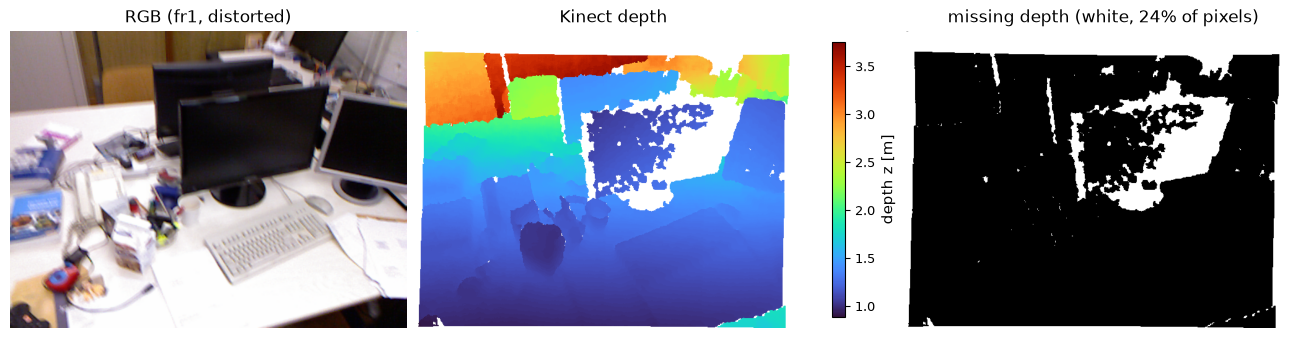

In [2]:
# --- Load one TUM RGB-D frame: RGB image + registered Kinect depth + intrinsics ---
# cvlab.tum.load_sequence associates rgb.txt / depth.txt / groundtruth.txt by timestamp
# (max 20 ms apart), exactly like TUM's associate.py.
seq = md.load_tum("fr1_desk")
FRAME = 450
rgb = seq.rgb(FRAME)  # (480, 640, 3) uint8, RGB order
gt = seq.depth(FRAME)  # (480, 640) float32 metres, 0 = missing
K = seq.camera.K  # calibrated fr1 RGB intrinsics in pixels
valid = md.valid_mask(gt)  # 0.1 m < z < 10 m
print(f"{len(seq)} associated frames in fr1_desk; using frame {FRAME}")
print(f"valid GT pixels {valid.mean():.1%} | depth {gt[valid].min():.2f}-{gt[valid].max():.2f} m, "
      f"median {np.median(gt[valid]):.2f} m")
print("K [px] =\n", K.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].imshow(rgb)
axes[0].set_title("RGB (fr1, distorted)")
im = axes[1].imshow(np.where(valid, gt, np.nan), cmap="turbo")
axes[1].set_title("Kinect depth")
fig.colorbar(im, ax=axes[1], label="depth z [m]", shrink=0.85)
axes[2].imshow(~valid, cmap="gray")
axes[2].set_title(f"missing depth (white, {(~valid).mean():.0%} of pixels)")
for ax in axes:
    ax.axis("off")
plt.show()

## Why one image only gives depth up to scale

A pinhole camera projects a 3D point $(X, Y, Z)$ (camera frame, $Z$ along the optical axis) to the pixel

$$u = f_x \frac{X}{Z} + c_x, \qquad v = f_y \frac{Y}{Z} + c_y .$$

Scale the whole scene by any $\lambda > 0$, $(X, Y, Z) \to (\lambda X, \lambda Y, \lambda Z)$, and the image
stays exactly the same. **Geometry alone cannot recover absolute scale from one view.** Networks
recover it, imperfectly, from learned priors (typical sizes of desks, keyboards and doors), and
that only works if they know the focal length. A wider lens makes the same desk look smaller, as
if it were further away.

The models in this notebook therefore output three different things:

| Output | Models | Relation to the true depth $Z^*$ | Unknowns |
|---|---|---|---|
| affine-invariant **disparity** $d$ | DA-V2 Small | $d \approx s / Z^* + t$ | scale $s$ **and** shift $t$ |
| **depth up to scale** $\hat Z$ | DA3-SMALL, DA3-BASE | $\hat Z \approx Z^* / s$ | scale $s$ |
| **metric depth** $Z$ | DA-V2 Metric-Indoor, DA3METRIC-LARGE | $Z \approx Z^*$ | none, *if* the priors and focal length are right |

Depth Anything V2 was trained like MiDaS: it predicts inverse depth up to an unknown scale and
shift, which allows mixing datasets with incompatible depth units. Depth Anything 3 predicts
depth directly (plus a camera), and its metric variant predicts a *canonical* depth that becomes
metres once multiplied by the focal length:

$$Z_{\text{metric}} = \frac{f_{\text{px}} \cdot y_{\text{net}}}{300},$$

where $f_{\text{px}}$ is the mean focal length at the resolution the network actually processed.

### Depth Anything V2 Small: relative disparity via `transformers`

The image processor resizes the image so that both sides are multiples of 14 (the ViT patch size)
with the short side at 518 px, then normalises it with ImageNet statistics. The head ends in a
ReLU, so the output is a non-negative disparity-like map with **no unit**: large values mean *close*.

In [3]:
# --- Depth Anything V2 Small (relative): what goes in and what comes out ---
# md.DepthModel wraps AutoImageProcessor + AutoModelForDepthEstimation; here we call the
# processor and network directly once, then use the wrapper (which resizes back to 640x480).
da2 = md.DepthModel("da2-small", device=str(device))
inputs = da2.processor(images=Image.fromarray(rgb), return_tensors="pt")
pix = inputs["pixel_values"].to(device)  # (1, 3, H', W'), H' and W' multiples of 14
with torch.inference_mode():
    disp_lowres = da2.net(pixel_values=pix).predicted_depth  # (1, H', W') disparity
print(f"{da2.n_params / 1e6:.1f} M parameters | network input {tuple(pix.shape)} "
      f"-> output {tuple(disp_lowres.shape)}")
pred_da2 = da2.predict(rgb)
d = pred_da2.values
print(f"output type '{pred_da2.output}', resized to {d.shape}, values {d.min():.2f} .. {d.max():.2f} (no unit)")

24.8 M parameters | network input (1, 3, 518, 686) -> output (1, 518, 686)
output type 'disparity', resized to (480, 640), values 0.01 .. 6.62 (no unit)


### Depth Anything 3: depth up to scale, plus a camera

Depth Anything 3 is an *any-view* model. Give it one image or many, and it predicts per-view
depth, a confidence map, and camera intrinsics and extrinsics (multi-view use is covered in project 10). It
is imported from the pinned upstream clone in `third_party/depth-anything-3`, not pip-installed,
because the package metadata pins `numpy<2`.

Importing `depth_anything_3.api` also imports `moviepy.editor`, which is used only to write
Gaussian-splatting videos. Installing moviepy 1.0.3 would downgrade a dependency of the shared
environment, so `md.stub_moviepy()` registers an empty placeholder module before the import. Depth
inference never touches it. By default DA3 resizes the longest side to 504 px (640x480 becomes 504x378) and runs in bf16.

In [4]:
# --- DA3-BASE: run one view and inspect the Prediction it returns ---
# The raw API returns numpy arrays at the processed resolution (378x504); md.DepthModel.predict
# resizes depth/confidence back to 480x640 and converts the predicted focal length to it.
print("moviepy stub inserted:", md.stub_moviepy())
da3 = md.DepthModel("da3-base", device=str(device))
out = da3.net.inference([rgb], process_res=504)  # depth_anything_3.specs.Prediction
print(f"{da3.n_params / 1e6:.1f} M parameters | depth {out.depth.shape} {out.depth.dtype}, "
      f"conf {out.conf.shape}")
print("predicted intrinsics at 504x378 [px]:\n", out.intrinsics[0].round(1))
pred_da3 = da3.predict(rgb)
print(f"predicted focal length at 640x480: {pred_da3.focal_px:.1f} px "
      f"(calibrated fx = {K[0, 0]:.1f}, fy = {K[1, 1]:.1f})")
print(f"depth up to scale: median {np.median(pred_da3.values):.3f} (arbitrary unit) "
      f"vs GT median {np.median(gt[valid]):.2f} m")

moviepy stub inserted: True


135.4 M parameters | depth (1, 378, 504) float32, conf (1, 378, 504)
predicted intrinsics at 504x378 [px]:
 [[400.1   0.  252. ]
 [  0.  407.9 189. ]
 [  0.    0.    1. ]]
predicted focal length at 640x480: 513.0 px (calibrated fx = 517.3, fy = 516.5)
depth up to scale: median 0.742 (arbitrary unit) vs GT median 1.27 m


### The remaining models: DA3-SMALL and the two metric models

DA3METRIC-LARGE needs the intrinsics $K$, because its output becomes metric only through
$f_{\text{px}}$. DA-V2 Metric-Indoor was fine-tuned on the synthetic Hypersim dataset with a
sigmoid head scaled to `max_depth = 20` m. Its focal-length assumption is implicit in the training
data, so it ignores $K$. The cell also times each forward pass and records peak VRAM for this one frame.
The benchmark in notebook 02 gives the proper numbers.

In [5]:
# --- DA3-SMALL, DA3METRIC-LARGE and DA-V2 Metric-Indoor Small through the same wrapper ---
# Models are loaded one at a time and freed afterwards; track_vram resets CUDA's peak-memory
# counter, so each number is "weights + activations" for one 640x480 frame (bf16 autocast).
preds = {"da2-small": pred_da2, "da3-base": pred_da3}
del da2, da3  # the two models above are no longer needed
md.free_cuda()
for key in ["da3-small", "da3metric-large", "da2-metric-indoor-small"]:
    with track_vram() as mem:
        model = md.DepthModel(key, device=str(device))
        model.predict(rgb, K)  # warm-up (cuDNN autotuning, allocator)
        t0 = time.perf_counter()
        preds[key] = model.predict(rgb, K)
        ms = (time.perf_counter() - t0) * 1000
    p = preds[key]
    print(f"{md.MODELS[key].label:>26s}: {model.n_params / 1e6:6.1f} M params | "
          f"{ms:6.1f} ms end-to-end ({p.extra['network_ms']:5.1f} ms network) | "
          f"peak {mem.peak_mb:5.0f} MiB | median output {np.median(p.values):.3f} "
          f"({'m' if p.output == 'metric' else 'no unit'})")
    del model
    md.free_cuda()

f_proc = md.da3_metric_focal(K, rgb.shape[:2], preds["da3metric-large"].proc_hw)
print(f"DA3METRIC-LARGE: processed at {preds['da3metric-large'].proc_hw}, f_px there = {f_proc:.1f}; "
      f"net output median {np.median(preds['da3metric-large'].raw):.3f} -> "
      f"{np.median(preds['da3metric-large'].values):.2f} m (GT median {np.median(gt[valid]):.2f} m)")

                 DA3-Small:   34.3 M params |   40.0 ms end-to-end ( 19.2 ms network) | peak   286 MiB | median output 0.812 (no unit)


           DA3Metric-Large:  334.2 M params |   87.5 ms end-to-end ( 62.2 ms network) | peak  1589 MiB | median output 1.201 (m)


 DA-V2 Metric-Indoor Small:   24.8 M params |   17.5 ms end-to-end ( 14.7 ms network) | peak   278 MiB | median output 1.492 (m)
DA3METRIC-LARGE: processed at (378, 504), f_px there = 407.1; net output median 0.885 -> 1.20 m (GT median 1.27 m)


### Raw outputs side by side

Before any alignment, each map has its own unit. Disparity is bright where the scene is *near*,
while depth is bright where it is *far*. Only the two metric models can share a colour scale with the sensor.

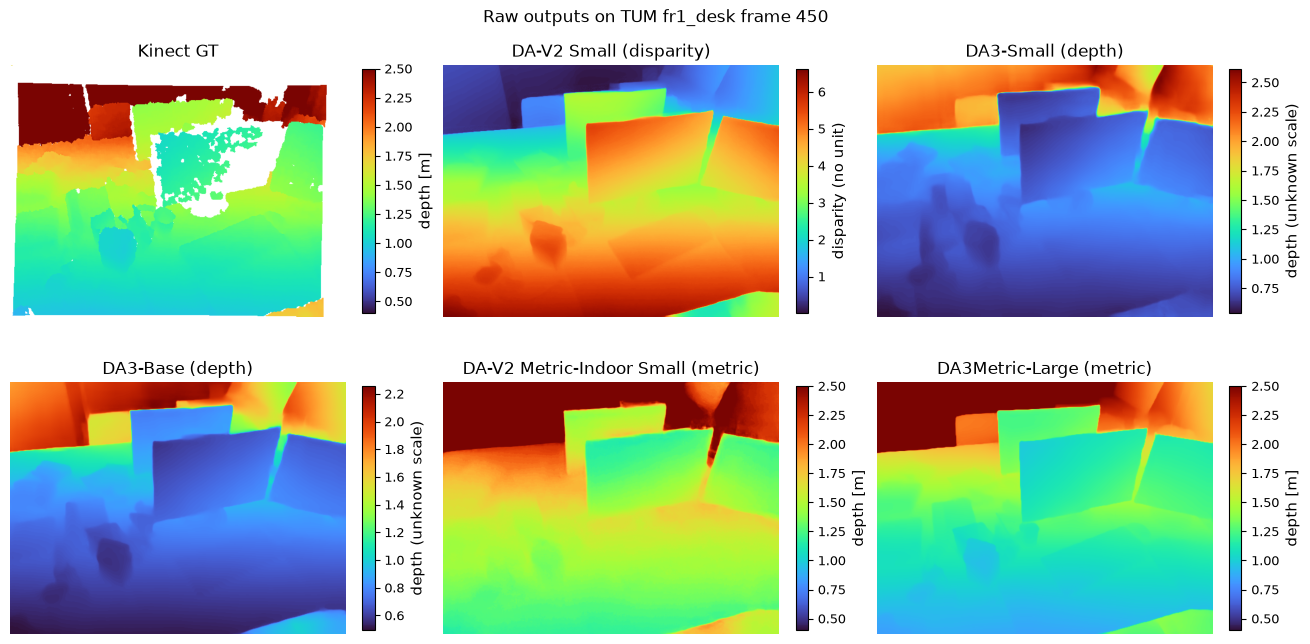

In [6]:
# --- Plot the raw network outputs with their own units ---
# Disparity is shown with an inverted sense of 'near/far' compared with depth; the colorbar
# labels make the unit (or lack of one) explicit.
order = ["da2-small", "da3-small", "da3-base", "da2-metric-indoor-small", "da3metric-large"]
units = {"disparity": "disparity (no unit)", "depth": "depth (unknown scale)", "metric": "depth [m]"}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
im = axes[0, 0].imshow(np.where(valid, gt, np.nan), cmap="turbo", vmin=0.4, vmax=2.5)
axes[0, 0].set_title("Kinect GT")
fig.colorbar(im, ax=axes[0, 0], label="depth [m]", shrink=0.8)
for ax, key in zip(axes.flat[1:], order):
    p = preds[key]
    lim = dict(vmin=0.4, vmax=2.5) if p.output == "metric" else {}
    im = ax.imshow(p.values, cmap="turbo", **lim)
    ax.set_title(f"{md.MODELS[key].label} ({p.output})")
    fig.colorbar(im, ax=ax, label=units[p.output], shrink=0.8)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Raw outputs on TUM fr1_desk frame {FRAME}")
plt.show()

## Aligning predictions to the sensor, in the right space

To score a prediction that is only defined up to scale (and shift), we first fit those unknowns
to the ground truth on the valid pixels $\Omega$, then measure what is left. That residual is the
*shape* error.

- **Median scaling** (depth up to scale): $s = \operatorname{median}_\Omega(Z^*) / \operatorname{median}_\Omega(\hat Z)$, then $Z = s\,\hat Z$.
- **Least-squares scale and shift** in the model's native space. With $x$ the prediction and $y$ the target,

$$ (s, t) = \arg\min_{s,t} \sum_{i \in \Omega} (s\,x_i + t - y_i)^2
\;\Rightarrow\; \begin{bmatrix} s \\ t \end{bmatrix} = (A^\top A)^{-1} A^\top y, \quad A = [\,x \;\; \mathbf 1\,]. $$

For DA-V2 the affine model holds in **inverse depth**. Fit $x = d$ against $y = 1/Z^*$, then invert:
$Z = 1/(s\,d + t)$, clamped to at most 10 m. Inverting $d$ first and fitting in depth space is
wrong, because $1/(s/Z + t)$ is not an affine function of $Z$. Exercise 1 measures how much worse it gets.
- **Raw metric**: no fitting at all. This is the only protocol a robot can use at run time
  without a depth sensor. The median-scaled metric result then separates *scale error* from *shape error*.

The scatter plots below make this concrete. Each point is one pixel (20 000 random valid pixels).

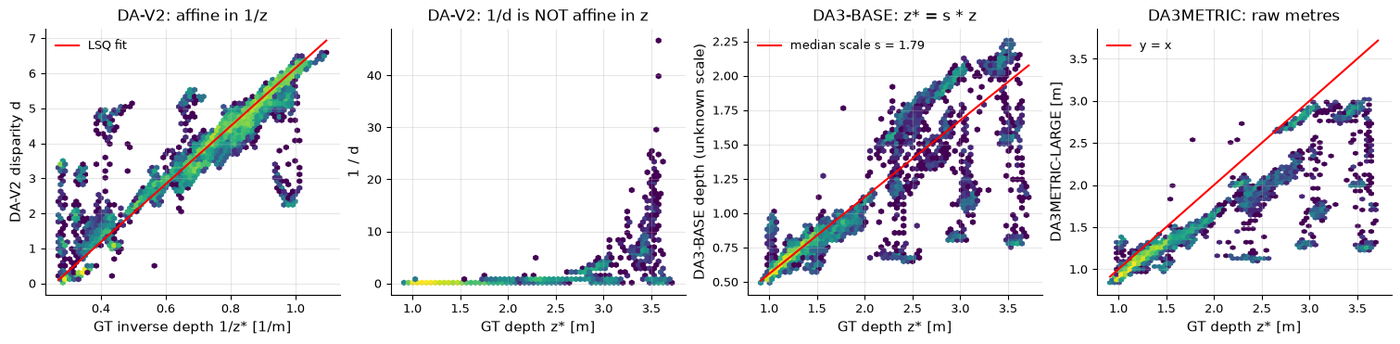

In [7]:
# --- Visualise the relation between predictions and sensor depth (per pixel) ---
# A straight line through the cloud means the alignment model (affine / pure scale) is right.
rng = np.random.default_rng(0)
idx = rng.choice(np.flatnonzero(valid), 20000, replace=False)
z_gt = gt.ravel()[idx]
d2 = pred_da2.values.ravel()[idx]
z3 = pred_da3.values.ravel()[idx]
zm = preds["da3metric-large"].values.ravel()[idx]
fit = md.evaluate_frame(pred_da2.values, "disparity", gt)["lsq"]
s3 = md.evaluate_frame(pred_da3.values, "depth", gt)["median"]["scale"]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
axes[0].hexbin(1 / z_gt, d2, gridsize=60, bins="log", cmap="viridis")
xs = np.linspace((1 / z_gt).min(), (1 / z_gt).max(), 50)
axes[0].plot(xs, (xs - fit["shift"]) / fit["scale"], "r-", lw=1.5, label="LSQ fit")
axes[0].set(xlabel="GT inverse depth 1/z* [1/m]", ylabel="DA-V2 disparity d", title="DA-V2: affine in 1/z")
axes[1].hexbin(z_gt, 1 / d2, gridsize=60, bins="log", cmap="viridis")
axes[1].set(xlabel="GT depth z* [m]", ylabel="1 / d", title="DA-V2: 1/d is NOT affine in z")
axes[2].hexbin(z_gt, z3, gridsize=60, bins="log", cmap="viridis")
zs = np.linspace(z_gt.min(), z_gt.max(), 50)
axes[2].plot(zs, zs / s3, "r-", lw=1.5, label=f"median scale s = {s3:.2f}")
axes[2].set(xlabel="GT depth z* [m]", ylabel="DA3-BASE depth (unknown scale)", title="DA3-BASE: z* = s * z")
axes[3].hexbin(z_gt, zm, gridsize=60, bins="log", cmap="viridis")
axes[3].plot(zs, zs, "r-", lw=1.5, label="y = x")
axes[3].set(xlabel="GT depth z* [m]", ylabel="DA3METRIC-LARGE [m]", title="DA3METRIC: raw metres")
for ax in axes[[0, 2, 3]]:
    ax.legend(loc="upper left")
viz.savefig(fig, PROJECT, "alignment_scatter")
plt.show()

## Metrics

With $p_i$ the aligned prediction and $g_i$ the sensor depth over the $N$ valid pixels:

$$\text{AbsRel} = \frac{1}{N}\sum_i \frac{|p_i - g_i|}{g_i}, \qquad
\text{RMSE} = \sqrt{\frac{1}{N}\sum_i (p_i - g_i)^2}\;[\mathrm{m}], \qquad
\delta_1 = \frac{1}{N}\,\Big|\Big\{ i : \max\!\big(\tfrac{p_i}{g_i}, \tfrac{g_i}{p_i}\big) < 1.25 \Big\}\Big| .$$

AbsRel is a relative error (0.05 means 5 % of the distance), RMSE is in metres and dominated by
far pixels, and $\delta_1$ is the fraction of pixels within 25 % of the truth (higher is better).
`md.evaluate_frame` applies every protocol valid for an output type and calls
`cvlab.metrics.depth_metrics`.

Note that the protocols optimise different things. The least-squares fit minimises the *squared*
error, which far pixels dominate, so it usually gives the best RMSE. The median scale is a
robust fit in *relative* terms, so it often gives the better AbsRel. Always report which alignment you used.

In [8]:
# --- Align + score every model with every valid protocol on this frame ---
# Disparity: LSQ in inverse depth. Depth up to scale: median and LSQ in depth.
# Metric: raw and median-scaled. 'main' marks the protocol used for the fair comparison.
main = {"disparity": "lsq", "depth": "median", "metric": "none"}
rows, aligned = [], {}
for key in order:
    p = preds[key]
    for proto, r in md.evaluate_frame(p.values, p.output, gt).items():
        aligned[key, proto] = r["depth"]
        rows.append({"model": md.MODELS[key].label, "output": p.output,
                     "protocol": md.PROTOCOL_LABELS[proto] + (" (1/z)" if p.output == "disparity" else ""),
                     "main": proto == main[p.output],
                     "AbsRel": r["abs_rel"], "RMSE [m]": r["rmse"], "delta1": r["delta1"],
                     "scale s": r["scale"], "shift t": r["shift"]})
frame_df = pd.DataFrame(rows)
frame_df.drop(columns="main").style.format(precision=3).hide(axis="index")

model,output,protocol,AbsRel,RMSE [m],delta1,scale s,shift t
DA-V2 Small,disparity,LSQ scale+shift (1/z),0.066,0.323,0.939,0.121,0.257
DA3-Small,depth,median scale,0.104,0.431,0.889,1.631,0.000
DA3-Small,depth,LSQ scale+shift,0.128,0.381,0.926,1.184,0.418
DA3-Base,depth,median scale,0.075,0.354,0.931,1.791,0.000
DA3-Base,depth,LSQ scale+shift,0.092,0.329,0.944,1.463,0.296
DA-V2 Metric-Indoor Small,metric,raw metric,0.169,0.371,0.870,1.000,0.000
DA-V2 Metric-Indoor Small,metric,median scale,0.094,0.402,0.901,0.860,0.000
DA3Metric-Large,metric,raw metric,0.127,0.399,0.899,1.000,0.000
DA3Metric-Large,metric,median scale,0.063,0.333,0.943,1.101,0.000


## Where are the errors? Per-pixel AbsRel maps

Averages hide structure. The map $|p - g|/g$ shows *where* a model is wrong: object boundaries
(depth discontinuities are smoothed by the network and slightly misregistered in the sensor), thin
structures, reflective screens, and the far end of the depth range. Grey pixels have no sensor depth.

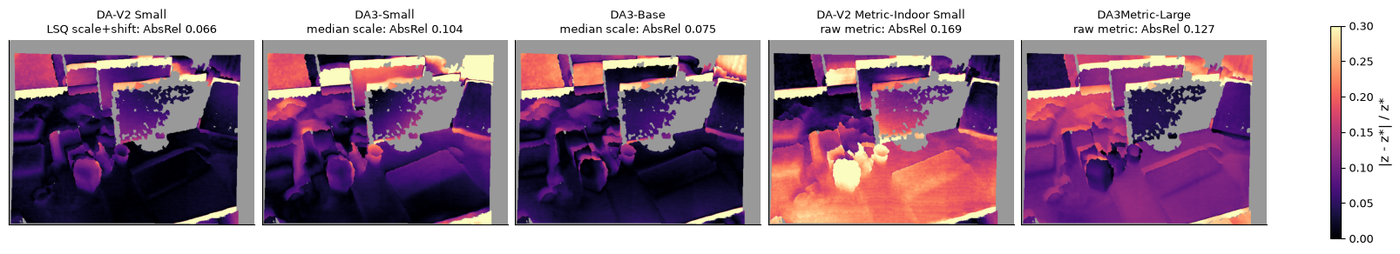

In [9]:
# --- Per-pixel relative error after each model's main protocol ---
# Main protocol = the one a fair comparison would use: LSQ for DA-V2 relative,
# median scale for DA3 relative, raw metres for the metric models.
fig, axes = plt.subplots(1, 5, figsize=(16, 2.9))
for ax, key in zip(axes, order):
    proto = main[preds[key].output]
    err = md.abs_rel_map(aligned[key, proto], gt)
    ax.set_facecolor("0.6")
    im = ax.imshow(err, cmap="magma", vmin=0, vmax=0.3)
    ax.set_title(f"{md.MODELS[key].label}\n{md.PROTOCOL_LABELS[proto]}: AbsRel {np.nanmean(err):.3f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, label="|z - z*| / z*", shrink=0.9)
viz.savefig(fig, PROJECT, "error_maps_frame")
plt.show()

## Results

The qualitative comparison puts every model on the **same metric colour scale** after its main
protocol, so the colours can be compared directly with the Kinect depth. The table summarises the
numbers measured on this single frame. Notebook 02 repeats the evaluation on 96 frames from two sequences.

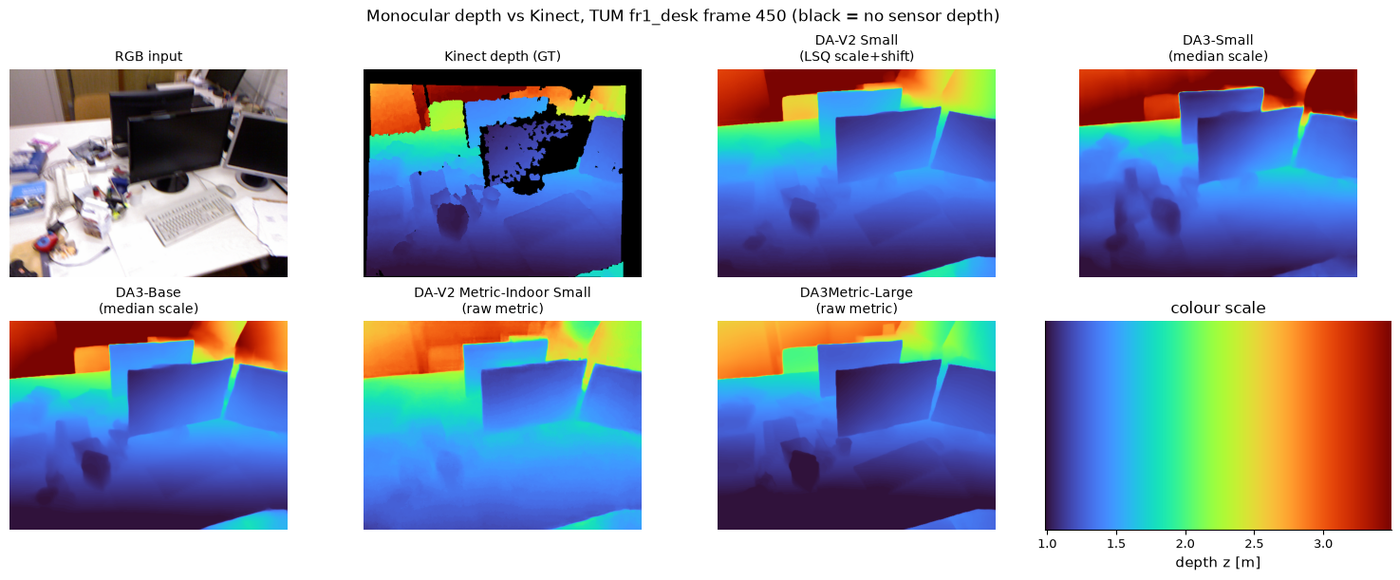

In [10]:
# --- Qualitative grid: RGB, sensor depth and every model on one metric colour scale ---
# Saved to assets/08_monocular_depth/ for the README (plus a small thumbnail).
vmin, vmax = np.percentile(gt[valid], [2, 98])
panels = [("RGB input", rgb), ("Kinect depth (GT)", viz.colorize_depth(gt, vmin, vmax))]
for key in order:
    proto = main[preds[key].output]
    panels.append((f"{md.MODELS[key].label}\n({md.PROTOCOL_LABELS[proto]})",
                   viz.colorize_depth(aligned[key, proto], vmin, vmax)))
fig, axes = plt.subplots(2, 4, figsize=(15, 6.0))
for ax, (title, img) in zip(axes.flat, panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
axes.flat[-1].imshow(np.linspace(vmin, vmax, 256)[None].repeat(12, 0), cmap="turbo",
                     aspect="auto", extent=[vmin, vmax, 0, 1])
axes.flat[-1].set_title("colour scale")
axes.flat[-1].set_xlabel("depth z [m]")
axes.flat[-1].set_yticks([])
axes.flat[-1].grid(False)
for ax in axes.flat[:-1]:
    ax.axis("off")
fig.suptitle(f"Monocular depth vs Kinect, TUM fr1_desk frame {FRAME} (black = no sensor depth)")
viz.savefig(fig, PROJECT, "qualitative_grid")
plt.show()

thumb, tax = plt.subplots(1, 2, figsize=(4.2, 1.6))
tax[0].imshow(rgb)
tax[1].imshow(viz.colorize_depth(preds["da3metric-large"].values, vmin, vmax))
for ax in tax:
    ax.axis("off")
viz.savefig(thumb, PROJECT, "thumb", dpi=100)
plt.close(thumb)

The summary table lists each model with its main protocol. The full table above also includes the
alternative protocols.

In [11]:
# --- Summary table (main protocol per model) ---
# 'scale s' of the raw metric rows is 1 by definition; the median-scaled rows above show
# how far the metric models are from the true scale on this frame.
summary = frame_df[frame_df["main"]].drop(columns=["main", "shift t"]).reset_index(drop=True)
summary.style.format(precision=3).hide(axis="index")

model,output,protocol,AbsRel,RMSE [m],delta1,scale s
DA-V2 Small,disparity,LSQ scale+shift (1/z),0.066,0.323,0.939,0.121
DA3-Small,depth,median scale,0.104,0.431,0.889,1.631
DA3-Base,depth,median scale,0.075,0.354,0.931,1.791
DA-V2 Metric-Indoor Small,metric,raw metric,0.169,0.371,0.870,1.000
DA3Metric-Large,metric,raw metric,0.127,0.399,0.899,1.000


### Takeaways

- **Know what your network outputs.** DA-V2 relative gives affine-invariant *disparity*, DA3
  any-view gives *depth up to scale*, and the metric models give metres. The first scatter plot shows
  that DA-V2 is linear only in inverse depth. Fitting it in depth space produces a curved residual and inflates the error (Exercise 1).
- **With per-frame alignment, every model reproduces the scene layout well.** That alignment uses
  the ground truth, though, so it is an *upper bound*. A robot without a depth sensor cannot do it at run time.
- **Metric depth is the deployable output, and it is the hardest.** Its error has two parts: the
  global scale (compare *raw metric* with *median scale* above) and the per-pixel shape. DA3METRIC's scale depends directly on the focal length you give it (Exercise 2).
- **The errors concentrate where the sensor itself struggles**: object boundaries, thin cables,
  the monitor and the far background. A single frame is anecdotal. Notebook 02 measures all five models on 96 frames, with runtime and VRAM.

## Exercises

Solutions: `projects/08_monocular_depth/solutions/solutions_01.py`.

**Exercise 1: the wrong alignment space.** Invert the DA-V2 disparity ($\hat Z = 1/d$), fit the
least-squares scale and shift in **depth** space, and compare AbsRel and $\delta_1$ with the
correct inverse-depth fit. Then plot the per-pixel errors of both against GT depth. Which depth range is hurt most?

In [12]:
# --- Exercise 1: LSQ scale+shift in depth space for a disparity model ---
# TODO: compute md.evaluate_frame(1.0 / np.maximum(pred_da2.values, 1e-6), "depth", gt, ["lsq"])
# and compare it with md.evaluate_frame(pred_da2.values, "disparity", gt)["lsq"].

**Exercise 2: focal-length sensitivity of DA3METRIC-LARGE.** Run DA3METRIC-LARGE with three intrinsics:
the calibrated fr1 $K$ ($f \approx 517$ px), the "ROS default" $f = 525$ px, and a wrong
$f = 400$ px (as if you had read the intrinsics of a different camera). How do the raw-metric AbsRel and the median scale factor change? Explain why using $Z = f\,y/300$.

In [13]:
# --- Exercise 2: DA3METRIC-LARGE with different focal lengths ---
# TODO: build K matrices with fx = fy in {517.3/516.5, 525, 400}, call
# md.DepthModel("da3metric-large").predict(rgb, K_variant) and score with md.evaluate_frame.

**Exercise 3: processing resolution.** DA3 resizes the longest side to `process_res` (default 504).
Evaluate DA3-BASE at `process_res` 280, 504 and 756 on this frame. Report the median-scaled
AbsRel and the forward time. Is there a sweet spot for an embedded robot?

In [14]:
# --- Exercise 3: DA3-BASE accuracy vs processing resolution ---
# TODO: loop over process_res in (280, 504, 756): md.DepthModel("da3-base", process_res=r),
# time .predict(rgb) after a warm-up call and score with md.evaluate_frame(..., ["median"]).